# puntuación aprendida de acciones: Métodos y evidencia

**Nivel:** 2 **Requisitos previos:** Políticas de acción aprendidas nivel 1 **Tiempo de lectura:** 25 minutos

**Pregunta:** ¿Cómo ordenan las políticas publicadas M03 y M04 las acciones admisibles al repetir el caso C05?

## Objetivos

Esta lección investiga la pregunta: ¿Cómo ordenan las políticas publicadas M03 y M04 las acciones admisibles al repetir el caso C05?

## Preparación

Las versiones siguientes están fijadas en `notebooks/requirements.txt` y también constan en los metadatos de este notebook; ```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```

In [1]:
# Importa la API publicada de políticas y las dependencias fijadas de gráficos y ejecución.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")


reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Datos
El notebook lee artefactos comprometidos del producto. Propietario: Neuraxis. Repositorio: https://github.com/fsantibanezleal/CAOS_Neuraxis. Licencia: Apache-2.0. El JSON es un artefacto experimental propio y congelado; este notebook no redistribuye datos de benchmarks externos;

Este notebook lee `data/derived/index.json` y las trazas listadas. La ejecución usa un espacio aislado de caso Reflexmesh; Para métodos aprendidos, descarga los activos públicos exactos con `python -m reflexmesh; Cli fetch-models --destination models/checkpoints --version v0; 01.000` y define `NEURAXIS_CHECKPOINTS` hacia esa carpeta; El manifiesto de publicación verifica los hashes. M09/M10 se leen desde trazas congeladas, salvo que `NEURAXIS_NOTEBOOK_MODEL` indique explícitamente un modelo Ollama local configurado;

Artefactos de esta lección:

- `data/derived/index.json` - `data/derived/benchmark-adequacy.json` - `data/derived/episodes/M03-C05-nominal-40000; - `data/derived/episodes/M04-C05-nominal-40000; json`

## Método

Un puntuador candidato asigna preferencias a características de cada candidato admisible; la calibración cambia la interpretación de puntajes, pero no demuestra beneficio causal. Los modelos logístico M03 y de árboles potenciados M04 heredan la distribución de entrenamiento, la construcción de etiquetas y la partición retenida. La acción sigue verificándose contra el conjunto admisible actual antes de ejecutarse. Esto importa cuando un candidato tiene alta probabilidad prevista, pero su revisión de recurso caducó o carece de capacidad. El ejemplo usa una sola observación C05 congelada para hacer inspeccionable el camino de características a elección. No mide la calidad de calibración: para eso se necesitan registros retenidos y un análisis de fiabilidad por grupos independientes. Dentro de esta repetición de puntuación aprendida de acciones (C05), un clasificador ajustado estima preferencias a partir de características y etiquetas, mientras la máscara sigue siendo una restricción de seguridad; En la comprobación reproducible de puntuación aprendida de acciones para C05, calibrar probabilidades y seleccionar acciones legales son propiedades distintas. En la comprobación reproducible de puntuación aprendida de acciones para C05, la reproducción C05 permite seguir características y puntuaciones, pero el modelo puede memorizar identificadores si la partición no reserva composiciones relevantes y no informa su denominador de evaluación. En este nivel, inspecciona juntas las características y la puntuación aprendida, y verifica que la acción elegida fuera admisible antes de atribuir el resultado al modelo.

### puntuación aprendida de acciones · nivel 2 | Verifica la auditoría y los bytes de cada traza antes de interpretar resultados.

In [2]:
# Carga las trazas propias y verifica sus hashes; nunca modifica los artefactos canónicos.
ROOT = Path("../../../").resolve()
index_path = ROOT / "data/derived/index.json"
index_bytes = index_path.read_bytes()
index = json.loads(index_bytes)
audit = json.loads((ROOT / "data/derived/benchmark-adequacy.json").read_text(encoding="utf-8"))
assert hashlib.sha256(index_bytes).hexdigest() == audit["index_sha256"]
selected_methods = ["M03", "M04"]
trace_methods = ["M03", "M04"]
sample_case = "C05"
seed = 40000
records = {}
for method_id in trace_methods:
    row = next(
        record
        for record in index["episodes"]
        if record["method_id"] == method_id
        and record["case_id"] == sample_case
        and record["variant"] == "nominal"
        and record["seed"] == seed
    )
    trace_path = ROOT / "data/derived" / row["path"]
    trace_bytes = trace_path.read_bytes()
    assert hashlib.sha256(trace_bytes).hexdigest() == row["sha256"]
    records[method_id] = json.loads(trace_bytes)
checkpoint_dir = Path(os.environ.get("NEURAXIS_CHECKPOINTS", str(ROOT / "models/checkpoints")))
planner_model = os.environ.get("NEURAXIS_NOTEBOOK_MODEL")
planner = OllamaPlanner(planner_model) if planner_model else None
print("Trazas verificadas por hash:", len(records))


Trazas verificadas por hash: 2


### puntuación aprendida de acciones · nivel 2 | Ejecuta las políticas publicadas y compara la corrida

### puntuación aprendida de acciones · nivel 2 | Compara la secuencia completa y no solo la primera acción

### puntuación aprendida de acciones · L2 | Construir la primera política ejecutable

Dentro de esta repetición de puntuación aprendida de acciones (C05), construye M03 para puntuación aprendida de acciones con la fábrica pública y conserva su contrato de observación antes de muestrear C05.

In [3]:
# Construye la primera política publicada mediante la fábrica pública.
primary_id = "M03"
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Política principal:", primary_id)


Política principal: M03


### puntuación aprendida de acciones · L2 | Ejecutar el método principal en el caso indicado

En la comprobación reproducible de puntuación aprendida de acciones para C05, de puntuación aprendida de acciones, el evaluador ejecuta M03 en C05 y deriva el éxito de la poscondición independiente, no de una traza reproducida.

In [4]:
# Ejecuta la política y verifica independientemente la poscondición del caso.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Éxito de tarea principal:", primary_result["metrics"]["task_success"])


Éxito de tarea principal: 1


### puntuación aprendida de acciones · L2 | Construir una política de comparación independiente

Crea M04 como objeto nuevo para impedir que el estado recurrente de M03 contamine la comparación

In [5]:
# Crea un objeto de política nuevo para la comparación emparejada.
secondary_id = "M04"
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Política de comparación:", secondary_id)


Política de comparación: M04


### puntuación aprendida de acciones · L2 | Ejecutar la comparación bajo condiciones idénticas

Esta comparación de nivel 2 ejecuta M04 en el mismo C05, variante nominal y semilla, y ilustra comportamiento, no estima una tasa poblacional.

In [6]:
# Usa el mismo caso, variante y semilla para la segunda política.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Éxito de tarea de comparación:", secondary_result["metrics"]["task_success"])


Éxito de tarea de comparación: 1


### puntuación aprendida de acciones · L2 | Agregar los dos episodios ejecutados

El agregador resume dos episodios ejecutados de puntuación aprendida de acciones, y las afirmaciones entre familias aún requieren el benchmark completo

In [7]:
# Agrega los resultados ejecutados con el evaluador descriptivo del paquete.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Ejecuciones nuevas de políticas:", len(fresh_runs))
print("Éxitos de las ejecuciones nuevas:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Ejecuciones nuevas de políticas: 2
Éxitos de las ejecuciones nuevas: 2


### puntuación aprendida de acciones · L2 | Resultados de políticas nuevas

El gráfico siguiente se calcula con los resultados de episodios de puntuación aprendida de acciones recién ejecutados en C05, no se copia de un artefacto congelado

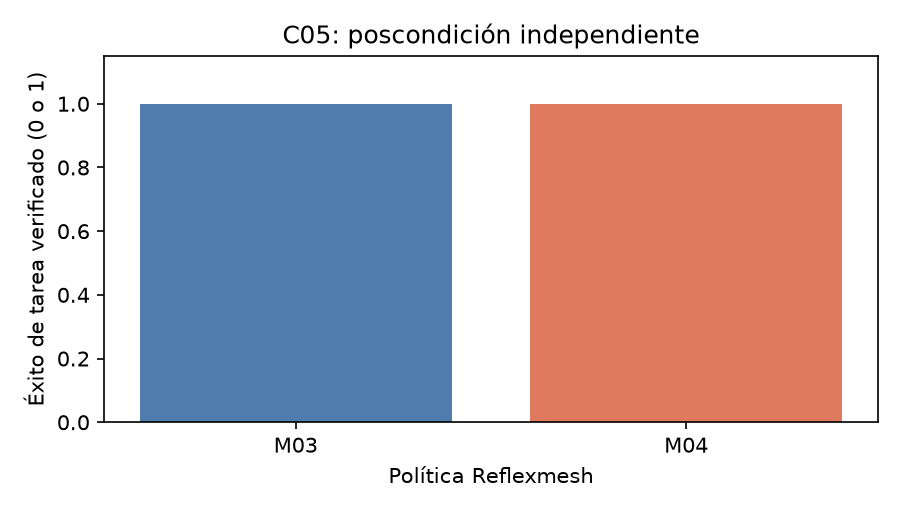

In [8]:
# Grafica los resultados verificados independientemente de las dos ejecuciones nuevas.
labels = list(fresh_runs)
success = [fresh_runs[name]["metrics"]["task_success"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, success, color=["#4f7cac", "#e07a5f"])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Éxito de tarea verificado (0 o 1)")
ax.set_xlabel("Política Reflexmesh")
ax.set_title(f"{sample_case}: poscondición independiente")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


Para puntuación aprendida de acciones, estas barras muestran resultados nuevos de poscondición de M03 y M04 en C05, Éxito vale 1 y falla 0. Lee el caso y la semilla antes de compararlas. En la comprobación reproducible de puntuación aprendida de acciones para C05, este episodio controlado ilustra el comportamiento, pero no es un intervalo de confianza ni establece generalización a otras tareas de software;

### puntuación aprendida de acciones · L2 | Tiempo registrado del controlador

En la comprobación reproducible de puntuación aprendida de acciones para C05, la figura de tiempos de puntuación aprendida de acciones usa registros congelados y verificados por hash para M03 y M04 en C05, no los tiempos dependientes de la máquina de episodios nuevos. Esta vista de nivel 2 para puntuación aprendida de acciones describe el entorno registrado bajo su caso, variante y semilla declarados.

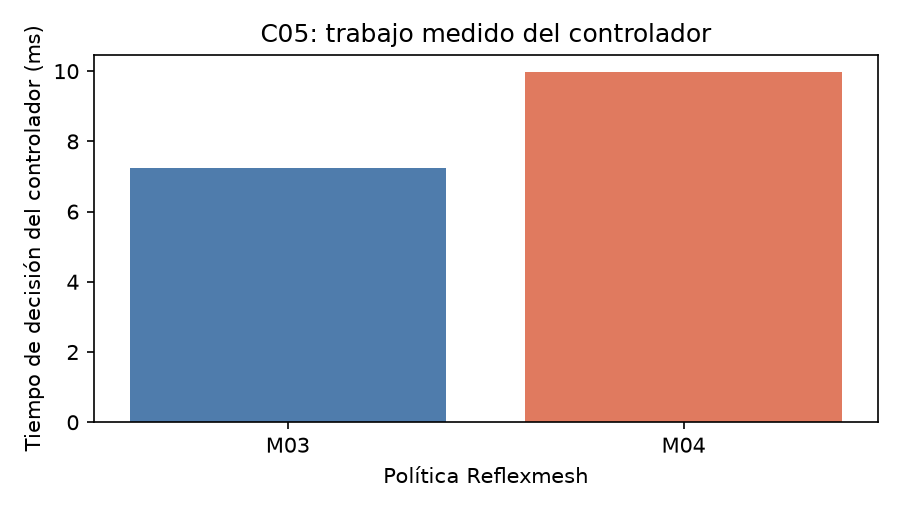

In [9]:
# Grafica el tiempo de control de los registros congelados y verificados por hash para los métodos emparejados.
labels = list(fresh_runs)
latencies = [records[name]["metrics"]["controller_ms"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, latencies, color=["#4f7cac", "#e07a5f"])
ax.set_ylabel("Tiempo de decisión del controlador (ms)")
ax.set_xlabel("Política Reflexmesh")
ax.set_title(f"{sample_case}: trabajo medido del controlador")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


La figura de nivel 2 para puntuación aprendida de acciones lee registros canónicos de M03/M04 en C05, variante nominal y semilla 40000, luego de verificar sus hashes en la frontera de datos. En la repetición emparejada de puntuación aprendida de acciones para C05, en esta lección de puntuación aprendida de acciones, el gráfico estable describe la latencia registrada y no afirma rapidez en la máquina actual.

## Resultados

**Respuesta:** La comparación de puntuación aprendida de acciones ejecuta 2 episodios nuevos de M03 y M04 bajo condiciones C05 idénticas; conserva a la vista las familias y semillas de puntuación aprendida de acciones, porque la matriz contiene tareas diseñadas y no una muestra poblacional.

En la comprobación reproducible de puntuación aprendida de acciones para C05, los checkpoints del paquete se publican como activos separados y no están versionados en este repositorio; En la comprobación reproducible de puntuación aprendida de acciones para C05, los resultados de los métodos ajustados son evaluaciones registradas y verificadas por hash, no modelos reajustados ahora; En la repetición emparejada de puntuación aprendida de acciones para C05, una tasa en familias diseñadas no estima el rendimiento en tareas de software arbitrarias;

En la comprobación reproducible de puntuación aprendida de acciones para C05, este paso de autoría no compromete salidas generadas; `scripts/run_notebooks; py` las ejecuta y guarda desde un kernel nuevo.

## Resumen

En la repetición emparejada de puntuación aprendida de acciones para C05, este ejemplo de puntuación aprendida de acciones usa C05 para mostrar el comportamiento bajo una condición declarada. En la comprobación reproducible de puntuación aprendida de acciones para C05, mantén el resultado medido separado de afirmaciones sobre inteligencia general para controlar software.



## Referencias
- [XGB](https://arxiv.org/abs/1603.02754) - [GRU](https://arxiv.org/abs/1406.1078) - [LINUCB](https://arxiv.org/abs/1003.0146)